# KerData — Préparation et analyse des données immobilières (Module 2)

Ce notebook rejoue **tout le pipeline de bout en bout** : lecture des 5 sources, types et statistiques, EDA, nettoyage, visualisations,
encodage, features, split, audit anti-fuite, pipeline final et évaluation. Chaque décision est justifiée dans `docs/justifications.md`.

**Exécution :** `jupyter nbconvert --to notebook --execute notebooks/02_preparation_analyse.ipynb` (ou « Run All »).
La première cellule lance `run_pipeline` ; l'évaluation sur le test est verrouillée : elle est lue, jamais recalculée.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE / "src"))
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 90)

from kerdata.pipeline import executer
res = executer(RACINE)           # étape 0 à compétence 9 ; l'évaluation du test est relue si déjà faite
m = res["tabs"]["mesures"]
print(f"{m['n']} lignes lues -> {m['propres']} propres | {m['avertissements']} avertissements | {m['quarantaine']} en quarantaine")
def csv(nom, **kw): return pd.read_csv(RACINE / "reports" / nom, **kw)
def fig(nom): display(Image(filename=str(RACINE / "reports" / "figures" / nom), width=900))

3184 lignes lues -> 2872 propres | 111 avertissements | 201 en quarantaine


## 0. Lecture et concaténation des 5 sources

Chaque source a son propre format (Excel, CSV `;` avec accents cassés, CSV `,`, JSON imbriqué, CSV sans en-tête). Les volumes lus sont comparés à la fiche de conception.

In [2]:
display(csv("volumes_etape0.csv"))

,source,attendu_fiche,lu,ecart
0,plateforme,875,875,0
1,agence,680,640,-40
2,particuliers,731,731,0
3,notaires,410,410,0
4,historique,528,528,0
5,TOTAL,3224,3184,-40


## 1. Types et statistiques descriptives (compétence 1)

Le prix des ventes est asymétrique (skew > 1) : on modélise `log(prix)`. Ventes et locations ne se mélangent pas (médianes ×230).

In [3]:
display(csv("comp1_types_par_source.csv").query("champ in ['prix','surface','date']")[["source","champ","type_reel","ecart","action"]])
display(csv("comp1_prix_vs_log.csv")[["population","n","median","skew_brut","skew_log"]])

,source,champ,type_reel,ecart,action
1,agence,date,texte mixte,298 à convertir (réparable),convertir (réparable)
6,agence,prix,numérique,5 valeurs <= 0,convertir + traiter le reste en comp 3
7,agence,surface,numérique,4 valeurs <= 0,convertir + traiter le reste en comp 3
12,historique,date,texte mixte,215 à convertir (réparable),convertir (réparable)
17,historique,prix,texte mixte,72 à convertir (réparable); 10 non convertibles (structurel),convertir + traiter le reste en comp 3
18,historique,surface,texte mixte,50 à convertir (réparable),convertir (réparable)
23,notaires,date,texte mixte,6 non convertibles (structurel),convertir + traiter le reste en comp 3
28,notaires,prix,numérique,14 vides,convertir + traiter le reste en comp 3
29,notaires,surface,numérique,aucun,type confirmé
34,particuliers,date,texte mixte,446 à convertir (réparable),convertir (réparable)


,population,n,median,skew_brut,skew_log
0,global (ventes+locations mélangées),3086,59412500.0,1.905,-1.396
1,segment location,478,327500.0,1.353,-0.300
2,segment vente,2608,74462000.0,1.864,-0.217
3,ventes — agence,529,80527000.0,1.833,-0.077
4,ventes — historique,518,67640000.0,1.675,-0.233
5,ventes — notaires,396,81635500.0,1.609,-0.098
6,ventes — particuliers,473,63826000.0,2.208,-0.173
7,ventes — plateforme,692,79126500.0,1.836,-0.276


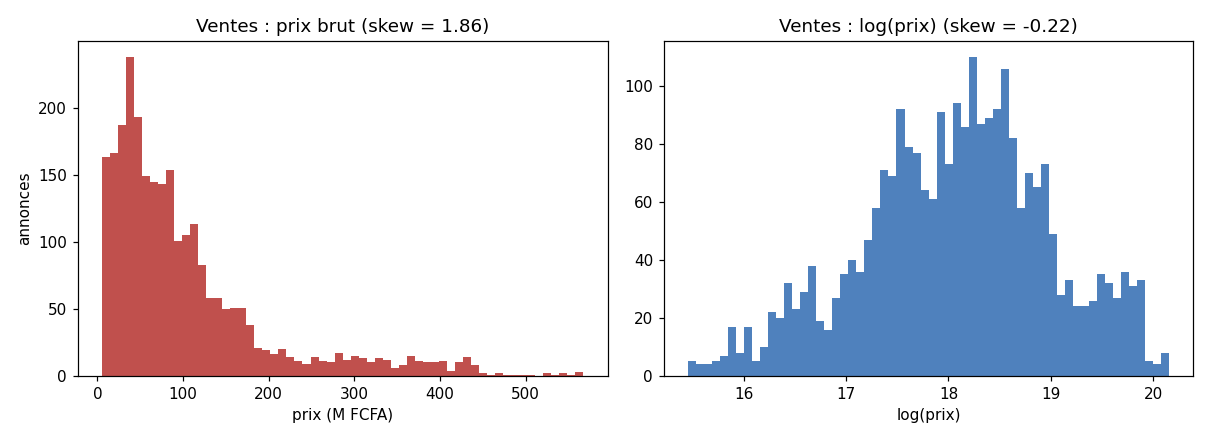

In [4]:
fig("comp1_prix_vs_log_ventes.png")

## 2. Analyse exploratoire (compétence 2)

Manquants et leur mécanisme, doublons, paradoxe de Simpson, tendance temporelle.

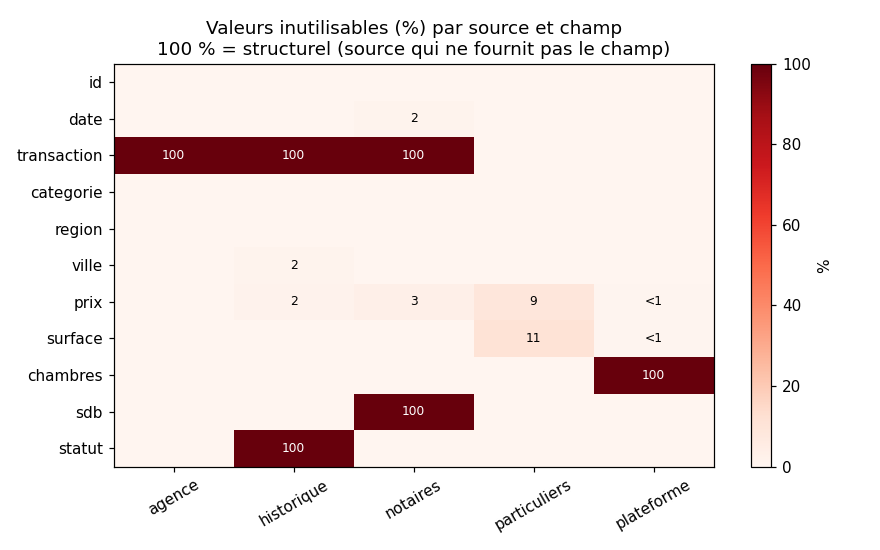

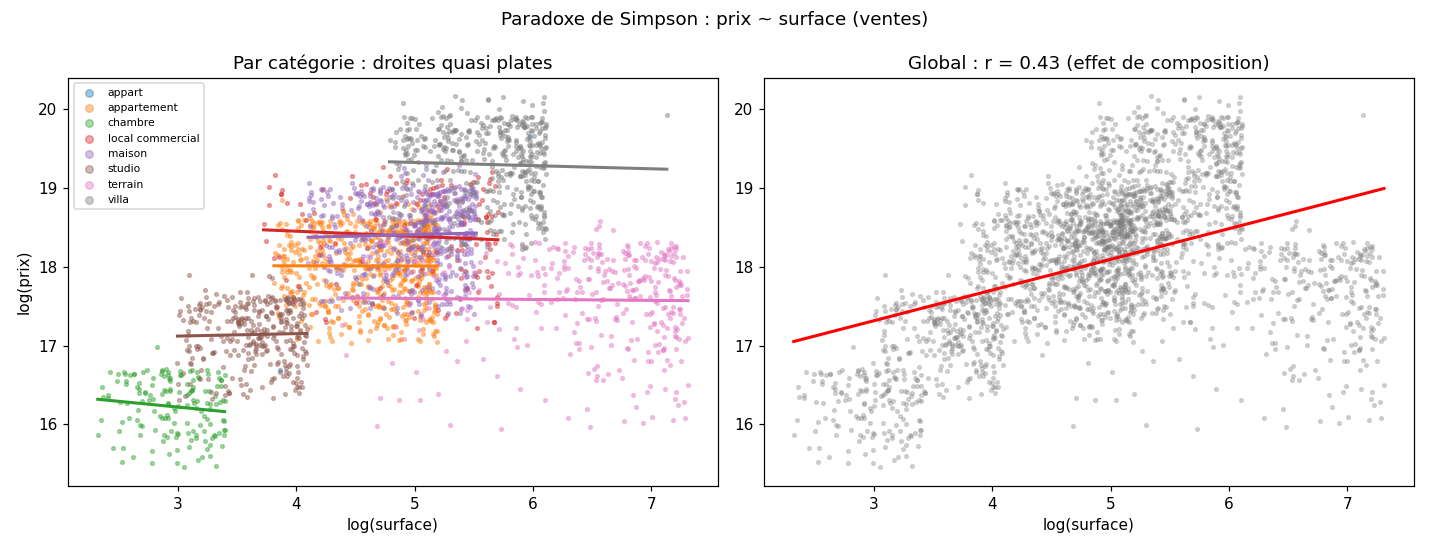

,echelle,n,tau,p_value,tendance_significative_5pct
0,annuelle (8 points),8,0.0000,1.0000,False
1,mensuelle (96 mois),96,-0.0162,0.8148,False
2,par vente (toutes sources),2597,-0.0025,0.8502,False
3,par vente (hors historique),2079,-0.0201,0.1690,False


In [5]:
fig("comp2_manquants.png"); fig("comp2_simpson_prix_surface.png")
display(csv("comp2_d6_robustesse.csv"))

## 3. Nettoyage (compétence 3) — les 6 mesures obligatoires

Chaque ligne finit dans un seul fichier : propres, avertissements ou quarantaine.

In [6]:
display(Markdown((RACINE / "sortie" / "rapport_qualite.md").read_text(encoding="utf-8").split("## Manquants")[0]))

# Rapport de qualité — KerData (corpus de 5 sources)

Généré automatiquement par `run_pipeline.py`. Chaque ligne des 3184 lignes lues finit dans **un seul** fichier.

## Bilan global

| Fichier | Lignes | Part |
|---|---|---|
| `donnees_propres.csv` | 2872 | 90.2 % |
| `avertissements.csv` (conservées, signalées) | 111 | 3.5 % |
| `quarantine.csv` (rejetées, avec raison) | 201 | 6.3 % |
| **Total** | **3184** | 100 % |

Corpus conservé (propres + avertissements) : **2983 lignes** (93.7 %), fichier `corpus_conserve.csv`.

## Les 6 mesures obligatoires

| # | Mesure | Valeur |
|---|---|---|
| 1 | Taux de manquants par colonne (état initial, toutes sources) | voir tableau « Manquants » ; colonnes les plus vides : transaction 49.6 %, chambres 27.5 %, statut 16.6 %, sdb 12.9 %, surface 2.5 %, prix 2.4 % |
| 2 | Doublons exacts | **15** (tous dans `plateforme`, identifiants dupliqués) |
| 3 | Doublons probables / conflits entre sources | **0** probables, **0** conflits (clé : date + ville + catégorie + surface, après correction du mojibake) |
| 4 | Erreurs de conversion par champ | prix **18**, surface **4**, date **6** (valeurs non vides non convertibles) |
| 5 | Corrigés / quarantaine / avertissements | **1407** lignes corrigées (1740 corrections tracées dans `journal_corrections.csv`) / **201** / **111** |
| 6 | Taux d'enregistrements entièrement conformes | **50.7 %** conformes d'emblée (sans correction ni alerte), **90.2 %** propres après corrections |



In [7]:
display(csv("comp3_manquants_mecanisme.csv")); display(csv("comp3_doublons.csv"))

,source,champ,vides,non_convertibles,pct_manquants_ou_illisibles,mecanisme,traitement
0,agence,transaction,640,0,100.0,structurel (100 % absent dans la source),"imputée par seuil de prix (3 M FCFA), provenance tracée, SANS indicateur de manque (fu..."
1,historique,transaction,528,0,100.0,structurel (100 % absent dans la source),"imputée par seuil de prix (3 M FCFA), provenance tracée, SANS indicateur de manque (fu..."
2,historique,ville,8,0,1.5,aléatoire (MCAR plausible),conservée avec avertissement (région présente)
3,historique,prix,0,10,1.9,aléatoire (MCAR plausible),"quarantaine (règle bloquante) : jamais imputé, c'est la cible"
4,historique,statut,528,0,100.0,structurel (100 % absent dans la source),conservé vide : source qui ne le fournit pas ; pas d'indicateur de manque
5,notaires,date,0,6,1.5,aléatoire (MCAR plausible),quarantaine (règle bloquante)
6,notaires,transaction,410,0,100.0,structurel (100 % absent dans la source),"imputée par seuil de prix (3 M FCFA), provenance tracée, SANS indicateur de manque (fu..."
7,notaires,prix,14,0,3.4,aléatoire (MCAR plausible),"quarantaine (règle bloquante) : jamais imputé, c'est la cible"
8,notaires,sdb,410,0,100.0,structurel (100 % absent dans la source),"conservé vide ; imputation par groupe dans le pipeline (fit sur train, comp 5/7), sans..."
9,particuliers,prix,61,2,8.6,aléatoire (MCAR plausible),"quarantaine (règle bloquante) : jamais imputé, c'est la cible"


,type,nombre,decision
0,exact (intra-source),15,"supprimé du corpus (mis en quarantaine, 1re occurrence conservée)"
1,"ID dupliqué, contenu différent",0,conservé avec avertissement (arbitrage manuel)
2,"probable inter-sources (même date, ville, catégorie, surface)",0,"signalé, jamais fusionné sans preuve"
3,"conflit (même bien, prix à plus de 20 %)",0,signalé seulement


## 4. Visualisations de restitution (compétence 4)

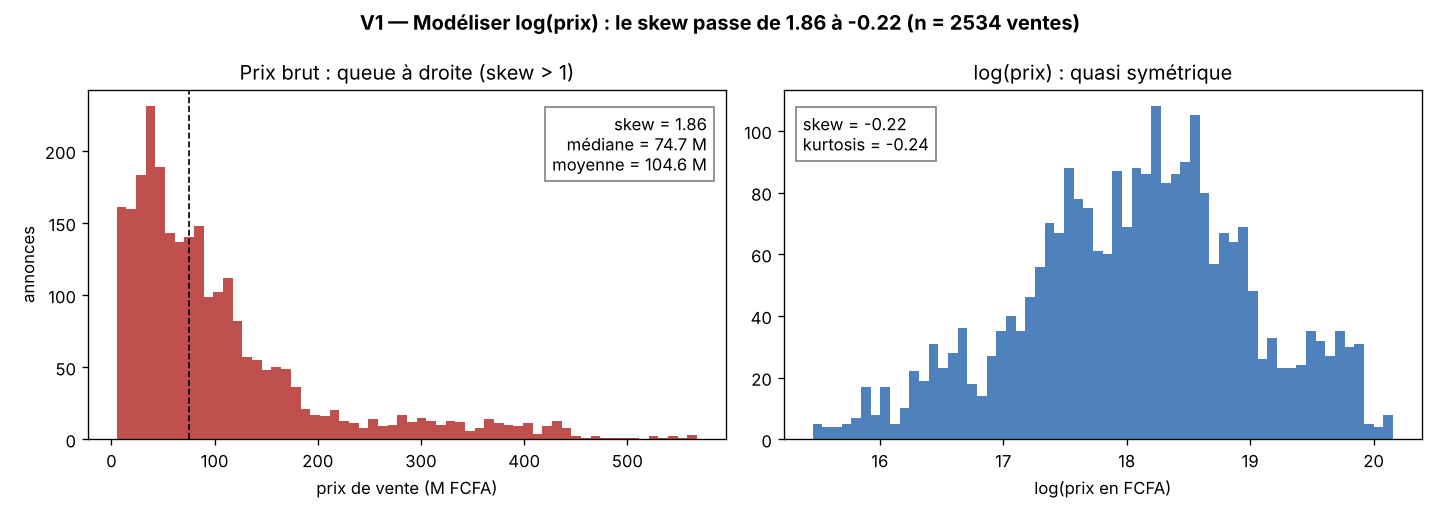

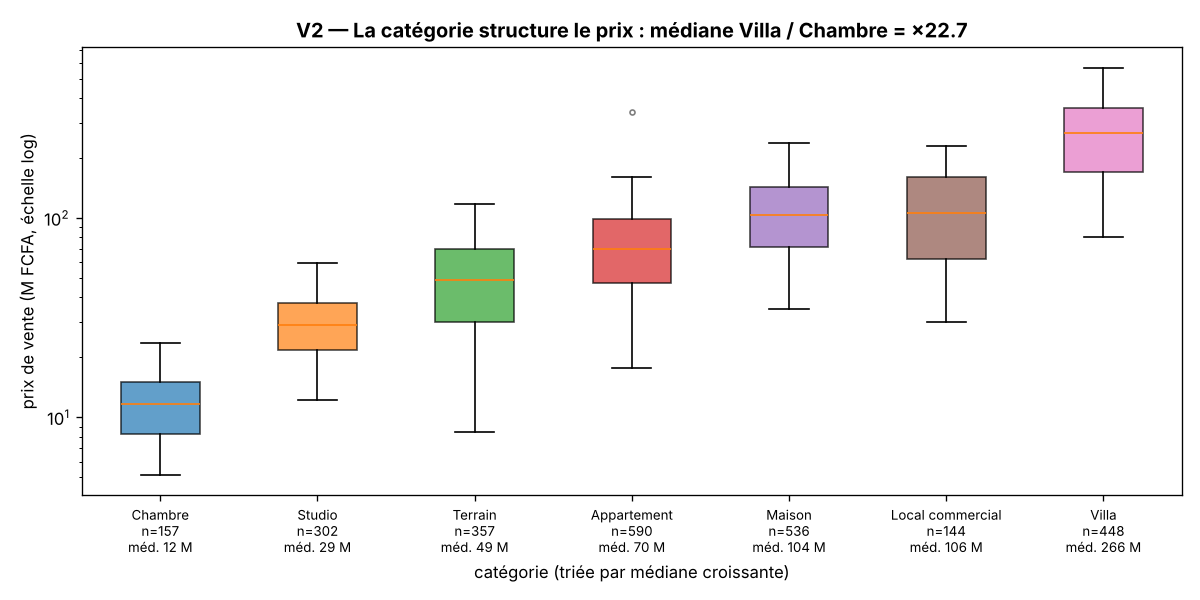

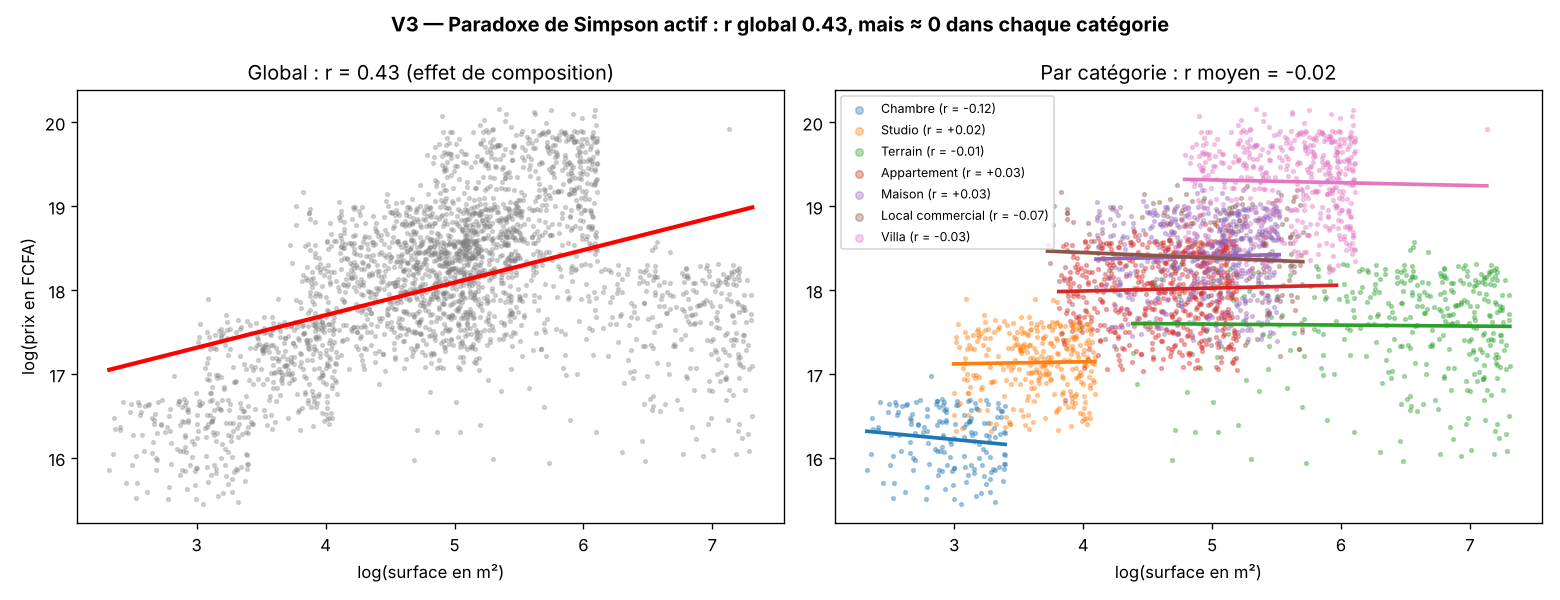

In [8]:
for f in ["v1_distribution_cible.png", "v2_prix_par_categorie.png", "v3_simpson_donnees_propres.png"]: fig(f)

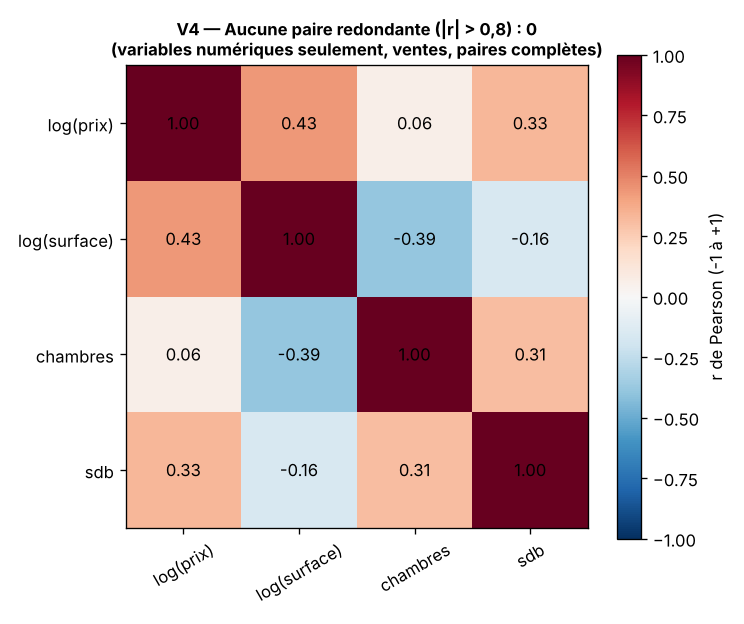

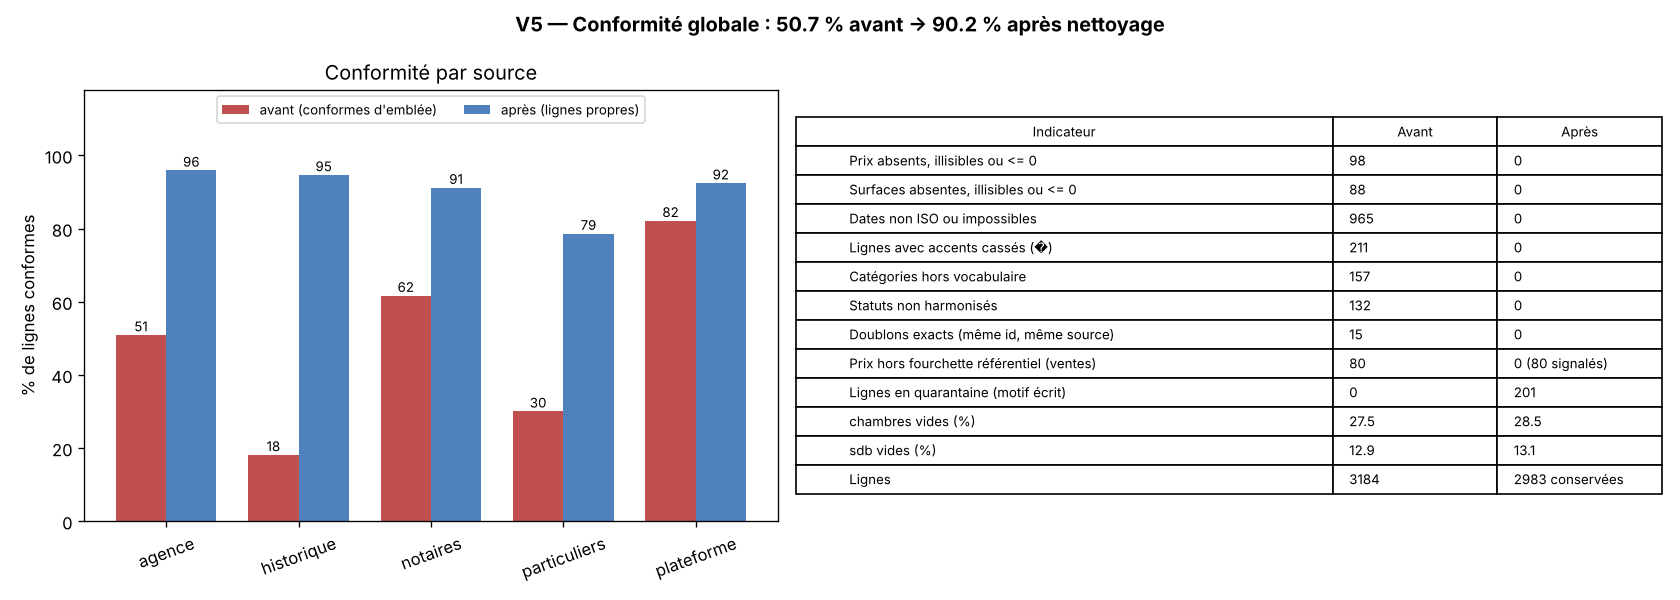

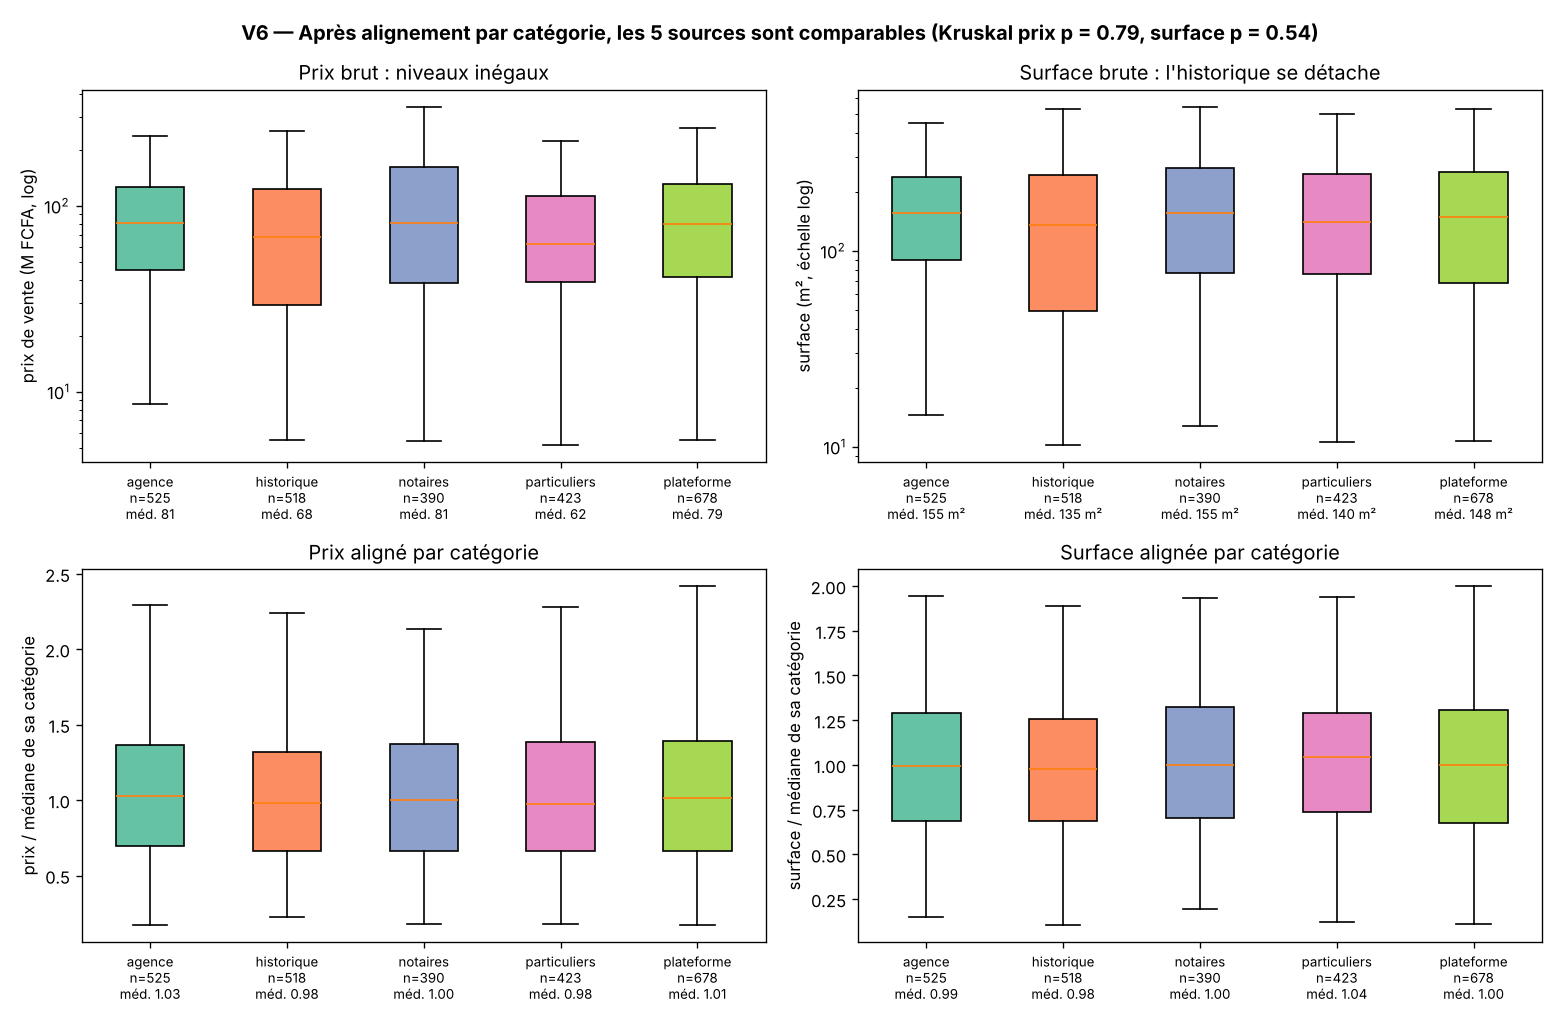

In [9]:
for f in ["v4_matrice_correlation.png", "v5_preuve_nettoyage.png", "v6_comparaison_sources.png"]: fig(f)

## 5. Encodage, features, split (compétences 5 à 7)

`statut`, `source` et `commune` sont exclues ; le split est aléatoire stratifié (Mann-Kendall p > 0,05) ; le test est scellé.

In [10]:
display(csv("comp5_tableau_variables.csv")[["variable","encodage_ou_scaler","justification"]])
display(csv("comp6_candidates.csv")[["variable","type","r2_seul","gain","gain_foret","decision"]].round(4))

,variable,encodage_ou_scaler,justification
0,prix (cible),log(prix) ; pas de scaler (c'est la cible),"skew 1.86 → -0.22 ; prix minimum = 5156000 > 0, le log est défini"
1,transaction,EXCLUE (constante sur le segment vente),"le modèle porte sur les ventes (comp 1, décision 1.6) : une seule valeur, variance nul..."
2,categorie,"one-hot (7 colonnes), handle_unknown=ignore","pas d'ordre ; porte l'essentiel du signal (η² = 0,74, comp 2) ; label encoding interdi..."
3,region,"one-hot (14 colonnes), handle_unknown=ignore",effectif minimum 161 ; explique ω² = 2.5 % du prix relatif (p = 5.7e-11)
4,ville (commune),EXCLUE du one-hot (frequency à tester en comp 6),"emboîtée dans région (exception : 1 ville à 2 régions, les lignes Dakar/Ziguinchor sig..."
5,statut,EXCLUE (fuite type 2),"V(source, statut) = 0.58 : proxy de la source (fuite type 4) ; aucun lien avec le prix..."
6,source,EXCLUE (audit seulement),"η² sur le prix relatif = 0.0005 (aucun signal) ; V(source, catégorie) = 0.17 : proxy d..."
7,transaction_origine,EXCLUE (fuite type 4),"V(source, transaction_origine) = 1.00 : reconstitue la source"
8,surface,log1p puis RobustScaler,"skew 2.49 → 0.04 ; outliers conservés (comp 3) → échelle robuste ; seule, non prédicti..."
9,chambres,imputation par catégorie (fit train) puis RobustScaler,"26.8 % vides, structurels (plateforme 100 %) ; aucun indicateur de manque (révélerait ..."


,variable,type,r2_seul,gain,gain_foret,decision
0,region,existante,-0.0008,0.0044,-0.0020,"GARDER (neutre, sens métier fort)"
1,surface_log,existante,0.1800,-0.0011,-0.0428,"GARDER (neutre, sens métier fort)"
2,annee,existante,-0.0021,-0.0004,-0.0064,"EXCLURE (neutre, sens métier faible)"
3,mois,existante,-0.0026,-0.0008,-0.0144,"EXCLURE (neutre, sens métier faible)"
4,chambres_sdb,existante,0.1186,-0.0004,-0.0156,"EXCLURE (neutre, sens métier faible)"
5,distance_dakar_km,créée,-0.0040,-0.0000,-0.0012,EXCLUE (redondante)
6,ville_frequence,créée,-0.0029,-0.0002,-0.0081,"EXCLURE (neutre, sens métier faible)"
7,surface_x_categorie,créée,0.6479,-0.0027,-0.0432,"EXCLURE (neutre, sens métier faible)"
8,surface_par_chambre,créée,0.0579,-0.0007,-0.0497,"EXCLURE (neutre, sens métier faible)"
9,prix_m2,fuite (test),0.2109,0.1352,0.1276,REJETÉE (fuite)


In [11]:
display(csv("comp7_split_ensembles.csv")); display(csv("comp7_preuve_strategie_mann_kendall.csv"))
print(json.dumps(json.loads((RACINE / "sortie" / "test_scelle.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1)[:600])

,ensemble,count,pourcentage,cible_ratio
0,train,1773,69.97,70%
1,val,380,15.00,15%
2,test,381,15.04,15%


,echelle,n_points,tau,p_value,decision
0,annuelle,8,0.0000,1.0000,pas de tendance → split aléatoire
1,mensuelle,96,-0.0241,0.7277,pas de tendance → split aléatoire
2,par vente,2530,-0.0034,0.8006,pas de tendance → split aléatoire


{
 "n_lignes": 381,
 "sha256_ligne_ids": "92a1f45006f5131665209be5a1e2e168f62d4760ec2c8add5dab7502a081a93e",
 "sha256_contenu": "416abcd763c5978ed8efc1f3770ee63f81b4bf4d529dfc8c39b0d9716befeccc",
 "graine": 42,
 "scelle_le": "2026-11-13",
 "utilisable_a_partir": "compétence 9 (évaluation finale unique)",
 "declaration": "Jeu de test scellé : interdit pour toute décision (features, seuils, hyperparamètres, modèle) avant la compétence 9."
}


## 6. Audit anti-fuite (compétence 8)

Les features finales ne permettent pas de deviner la source ; `annee+mois` et les indicateurs de manque la révèlent.

In [12]:
display(csv("comp8_detectabilite_source.csv")); display(csv("comp8_plausibilite_score.csv"))

,ensemble_de_features,auc_macro,precision,precision_baseline,verdict
0,features finales (categorie + region + surface_log),0.5429,0.2730,0.2673,source indétectable : OK
1,categorie seule,0.5605,0.2893,0.2673,source indétectable : OK
2,region seule,0.4839,0.2346,0.2673,source indétectable : OK
3,surface_log seule,0.5019,0.2758,0.2673,source indétectable : OK
4,annee + mois (candidates exclues),0.6490,0.4089,0.2673,RÉVÈLE LA SOURCE
5,chambres + sdb imputées,0.5489,0.2831,0.2673,source indétectable : OK
6,indicateur chambres_vide (jamais créés),0.7301,0.4743,0.2673,RÉVÈLE LA SOURCE
7,indicateur sdb_vide (jamais créés),0.6776,0.4219,0.2673,RÉVÈLE LA SOURCE
8,2 indicateurs de manque (jamais créés),0.8564,0.6289,0.2673,RÉVÈLE LA SOURCE


,modele,r2_cv_train,seuil_suspect,verdict
0,Ridge,0.7491,0.95,"plausible (< 0,95)"
1,forêt aléatoire,0.7246,0.95,"plausible (< 0,95)"


## 7. Pipeline final et évaluation (compétence 9)

Le pipeline sérialisé est rechargé depuis le disque et appliqué à une ligne brute de chaque source.

In [13]:
import joblib
from kerdata.modele import adapter_ligne, lignes_natives
modele = joblib.load(RACINE / "models" / "pipeline_preparation.joblib")
print(type(modele).__name__, "->", [n for n, _ in modele.regressor_.steps])
for source, ligne in lignes_natives(RACINE).items():
    X = adapter_ligne(source, ligne)
    print(f"{source:13} {X.iloc[0].to_dict()} -> {modele.predict(X)[0] / 1e6:8.1f} M FCFA")

TransformedTargetRegressor -> ['normalisation', 'preparation', 'modele']


agence        {'categorie': 'Studio', 'region': 'Fatick', 'surface': '35.7'} ->     27.2 M FCFA
historique    {'categorie': 'Studio', 'region': 'Thi�s', 'surface': '24.2'} ->     27.3 M FCFA
notaires      {'categorie': 'Villa', 'region': 'Sédhiou', 'surface': '392.1'} ->    234.5 M FCFA
particuliers  {'categorie': 'Studio', 'region': 'Fatick', 'surface': 50.0} ->     27.4 M FCFA
plateforme    {'categorie': 'Villa', 'region': 'Dakar', 'surface': '275.8'} ->    318.4 M FCFA


In [14]:
for k in ["v3", "v4"]: display(res["comp9"]["verifs"][k])
t = json.loads((RACINE / "reports" / "comp9_evaluation_finale.json").read_text(encoding="utf-8"))
print("Évaluation finale (réalisée une seule fois le", t["realisee_le"], ") :")
display(pd.DataFrame({"Ridge": t["global_"], "baseline médiane catégorie": t["baseline_mediane_categorie"]}).T.round(4))
display(pd.DataFrame(t["par_categorie"]).T.round(3)[["n", "r2_log", "mdape_pct"]])

,controle,exec_1,exec_2,identique
0,empreinte des coefficients (exécution 1 / 2),1bc3b7192d92c61e,1bc3b7192d92c61e,True
1,empreinte des prédictions de validation,f4e52970237eb708,f4e52970237eb708,True
2,graine du split (comp 7),42,42,True


,echantillon,n,ecart_maximal_fcfa,predictions_identiques
0,validation,60,0.0,True
1,test (caractéristiques seules),60,0.0,True
2,fichier models/pipeline_preparation.joblib,0,0.0,True


Évaluation finale (réalisée une seule fois le 2026-11-17 ) :


,n,r2_log,rmse_log,mdape_pct,mae_fcfa
Ridge,381.0,0.7307,0.4836,35.9221,3.845587e+07
baseline médiane catégorie,381.0,0.7126,0.4996,34.0919,3.904154e+07


,n,r2_log,mdape_pct
Appartement,89.0,0.047,33.508
Chambre,24.0,-0.110,27.190
Local commercial,22.0,-0.031,39.925
Maison,80.0,-0.129,33.835
Studio,45.0,-0.025,34.250
Terrain,53.0,-0.007,47.710
Villa,68.0,0.028,36.436


## 8. Conclusion et limites

- **Données :** 3184 lignes lues, 2872 propres, 111 avertissements, 201 en quarantaine ; 40 lignes d'agence manquent par rapport à la fiche (non comblées).
- **Résultat :** le prix se prédit surtout par la **catégorie** (η² = 0,74). À l'intérieur d'une catégorie, ni la surface ni la région n'expliquent le prix (paradoxe de Simpson) : le pipeline fait à peine mieux que la médiane de la catégorie (R² log 0,731 contre 0,713 sur le test).
- **Rigueur :** aucune fuite détectée (`statut`, `source`, `annee`, indicateurs de manque écartés), fit sur le train seul, test scellé et évalué une seule fois.
- **Limites :** l'historique ne couvre que 2018-2020 ; 4 ventes datées de 2028 restent en avertissement ; le seuil de 3 M FCFA ventes/locations a été observé avant le split ; la performance n'est pas extrapolable à un marché futur.